# Quantum gravity: scales, effective theories, and evidence

Evidence-led calculations; explanatory companion: [quantum_gravity.md](../premium/quantum_gravity.md). Run from the project root or this notebook directory. Plotted curves are theoretical illustrations, never quantum-gravity observations.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.constants import G, c, hbar, k_B, M_sun

# No external files are required; sourced measurements are transcribed below.
HERE = Path.cwd()
PROJECT = next((p for p in [HERE, *HERE.parents, HERE / "research/projects/exotic-compact-objects"] if (p / "notebooks/24_quantum_gravity.ipynb").is_file()), HERE)
print("Project root:", PROJECT.resolve())
print("Inputs are constants, values transcribed from cited papers, or explicitly chosen toy parameters; no external catalog is loaded.")

Project root: /home/dawe/Projects/astro-science/research/projects/exotic-compact-objects
Inputs are constants, values transcribed from cited papers, or explicitly chosen toy parameters; no external catalog is loaded.


## 1. Dimensional construction of Planck scales

Measured inputs: $G$, $c$, $\hbar$, $k_B$ from Astropy/CODATA (the exactness/uncertainty status of constants follows SI/CODATA). Derivation: assume $\ell=G^a\hbar^bc^d$; matching mass, length, and time dimensions gives $-a+b=0$, $3a+2b+d=1$, and $-2a-b-d=0$. Thus $b=a$, $d=-3a$, $2a=1$, so $\ell_P=\sqrt{\hbar G/c^3}$. Then $t_P=\ell_P/c$, $m_P=\sqrt{\hbar c/G}$, $E_P=m_Pc^2$, and $T_P=E_P/k_B$. These are derived scales, not observed objects.

In [2]:
# Symbolic verification of dimensions and identities; exponents are (M,L,T).
Gdim = sp.Matrix([-1, 3, -2]); hdim = sp.Matrix([1, 2, -1]); cdim = sp.Matrix([0, 1, -1])
a,b,d = sp.symbols('a b d')
sol = sp.solve([sp.Eq(-a+b,0), sp.Eq(3*a+2*b+d,1), sp.Eq(-2*a-b-d,0)], [a,b,d])
assert sol == {a: sp.Rational(1,2), b: sp.Rational(1,2), d: sp.Rational(-3,2)}
assert sp.simplify((Gdim/2+hdim/2-3*cdim/2) - sp.Matrix([0,1,0])) == sp.zeros(3,1)
Gv, hv, cv, kv = G.si, hbar.si, c.si, k_B.si
lP = np.sqrt((hbar*G/c**3).to(u.m**2)).to(u.m)
tP = (lP/c).to(u.s)
mP = np.sqrt((hbar*c/G).to(u.kg**2)).to(u.kg)
EP = (mP*c**2).to(u.J)
TP = (EP/k_B).to(u.K)
planck = pd.DataFrame({'derived scale':['length','time','mass','energy','temperature'], 'value':[lP.value,tP.value,mP.value,EP.value,TP.value], 'unit':['m','s','kg','J','K']})
planck

,derived scale,value,unit
0,length,1.616255e-35,m
1,time,5.391246e-44,s
2,mass,2.176434e-08,kg
3,energy,1.956082e+09,J
4,temperature,1.416784e+32,K


## 2. Schwarzschild–Compton crossover

Definitions: the Schwarzschild radius for a classical, nonrotating, uncharged mass is $r_s=2Gm/c^2$; the reduced Compton wavelength is $\bar{\lambda}_C=\hbar/(mc)$. Equate them: $2Gm/c^2=\hbar/(mc)$; multiply by $mc^2$: $2Gm^2=\hbar c$; hence $m=m_P/\sqrt{2}$. Substitution yields both lengths $\sqrt{2}\ell_P$. This order-unity crossover is heuristic; it does not establish a production threshold.

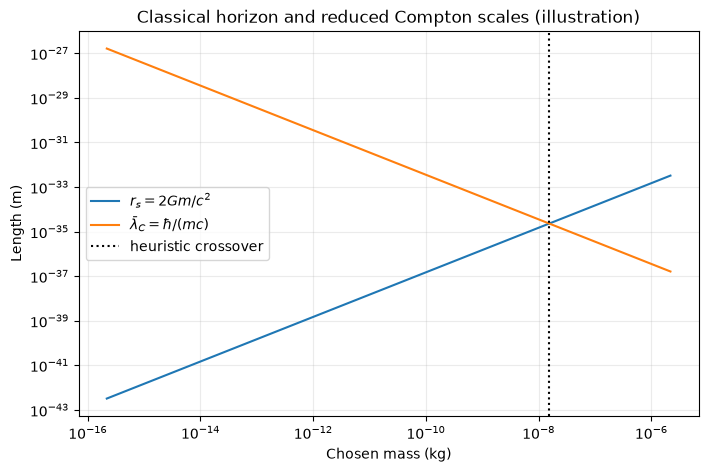

In [3]:
m = sp.symbols('m', positive=True); Gs, hs, cs = sp.symbols('G hbar c', positive=True)
assert sp.simplify(sp.solve(sp.Eq(2*Gs*m/cs**2, hs/(m*cs)), m)[0] - sp.sqrt(hs*cs/(2*Gs))) == 0
mp = sp.sqrt(hs*cs/Gs); lp = sp.sqrt(hs*Gs/cs**3)
assert sp.simplify((2*Gs*(mp/sp.sqrt(2))/cs**2) / (sp.sqrt(2)*lp) - 1) == 0
# A grid of chosen masses, not a measured sample.
masses = np.logspace(-8, 2, 500) * mP
r_s = (2*G*masses/c**2).to(u.m)
lam = (hbar/(masses*c)).to(u.m)
fig,ax=plt.subplots(figsize=(8,5)); ax.loglog(masses.value, r_s.value, label=r'$r_s=2Gm/c^2$'); ax.loglog(masses.value, lam.value, label=r'$\bar{\lambda}_C=\hbar/(mc)$')
ax.axvline((mP/np.sqrt(2)).value,color='k',ls=':',label='heuristic crossover')
ax.set(xlabel='Chosen mass (kg)',ylabel='Length (m)',title='Classical horizon and reduced Compton scales (illustration)'); ax.grid(True,which='both',alpha=.25); ax.legend(); plt.show()

## 3. Bekenstein–Hawking entropy: algebra and units

For Schwarzschild, $A=4\pi r_s^2=4\pi(2GM/c^2)^2=16\pi G^2M^2/c^4$. The semiclassical area law is $S_{BH}=k_BA/(4\ell_P^2)$. Using $\ell_P^2=\hbar G/c^3$ gives $S_{BH}=k_BAc^3/(4\hbar G)=4\pi k_BGM^2/(\hbar c)$. The ratio $A/(4\ell_P^2)$ is dimensionless because both numerator and denominator are area; multiplication by $k_B$ restores entropy units. This thermodynamic entropy does not by itself specify experimentally counted microstates.

In [4]:
M, Gs, cs, hs, kbs = sp.symbols('M G c hbar k_B', positive=True)
rs = 2*Gs*M/cs**2; area = 4*sp.pi*rs**2; lp2 = hs*Gs/cs**3
S_area = kbs*area/(4*lp2); S_mass = 4*sp.pi*kbs*Gs*M**2/(hs*cs)
assert sp.simplify(S_area-S_mass)==0
# Solar-mass example is a derived scale from measured solar mass and constants, not an entropy observation.
Ms = M_sun
area_sun = (4*np.pi*(2*G*Ms/c**2)**2).to(u.m**2)
S_sun = (k_B*area_sun/(4*lP**2)).to(u.J/u.K)
print(f'Schwarzschild area for 1 solar mass: {area_sun:.4g}')
print(f'Semiclassical Bekenstein-Hawking entropy: {S_sun:.4g}')
print('Dimensionless area in Planck units:', (area_sun/(4*lP**2)).decompose())

Schwarzschild area for 1 solar mass: 1.096e+08 m2
Semiclassical Bekenstein-Hawking entropy: 1.448e+54 J / K
Dimensionless area in Planck units: 1.0488914478465575e+77


## 4. EFT suppression, not a UV prediction

The EFT organizes corrections in powers of characteristic energy relative to a cutoff. The displayed $\epsilon^2=(E/E_P)^2$ assumes a unit coefficient solely to visualize dimensional suppression; real terms depend on operators, Wilson coefficients, symmetries, and the actual cutoff. $E/E_P\ll1$ signals a controlled expansion regime; reaching unity signals loss of this simple expansion, not known high-energy behavior. Donoghue's low-energy EFT framework and Wallace's distinction between predictive low-energy theory and unknown UV completion are cited in the companion section.

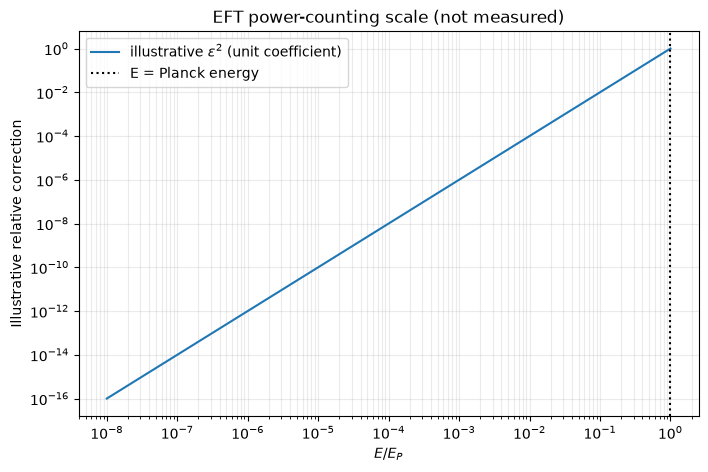

In [5]:
fraction = np.logspace(-8, 0, 300)
fig,ax=plt.subplots(figsize=(8,5)); ax.loglog(fraction, fraction**2, label=r'illustrative $\epsilon^2$ (unit coefficient)')
ax.axvline(1,color='k',ls=':',label='E = Planck energy'); ax.set(xlabel=r'$E/E_P$',ylabel='Illustrative relative correction',title='EFT power-counting scale (not measured)'); ax.grid(True,which='both',alpha=.25); ax.legend(); plt.show()

## 5. Conditional Lorentz-violating propagation example

Model assumption only: $E^2\simeq p^2c^2[1+\eta(E/E_{QG})^n]$, with $|\eta|(E/E_{QG})^n\ll1$. Derivation: start with $E^2=p^2c^2[1+\eta(E/E_{QG})^n]$ and define $x=E/E_{QG}$. Solving for momentum gives $p(E)=(E/c)[1+\eta x^n]^{-1/2}\simeq(E/c)[1-\eta x^n/2]$ for $|\eta x^n|\ll1$. Differentiate: $dp/dE\simeq c^{-1}[1-(n+1)\eta x^n/2]$. Thus $v_g=dE/dp=(dp/dE)^{-1}\simeq c[1+(n+1)\eta x^n/2]$, so $\delta v/c\simeq(n+1)\eta x^n/2$. For a flat-space path at fixed energy, $\Delta t=L/v_g-L/c\simeq-(n+1)\eta Lx^n/(2c)$ (sign follows convention). The plotted choices $n=1$, $\eta=1$, $E_{QG}=E_P$, $L=1$ Gpc are illustrative, not fitted data, bounds, or a preferred theory. Real limits require source-lag modeling, cosmological redshift integration, detector response, and a specified operator. Liberati & Maccione review the model dependence; no direct quantum-gravity dispersion measurement is claimed.

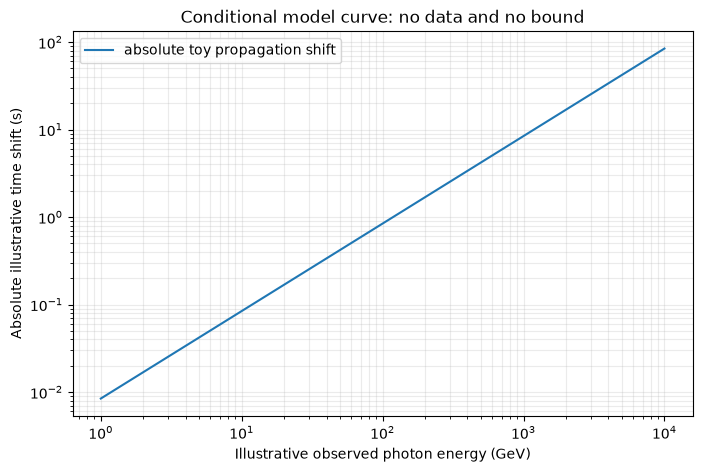

Toy parameter choices: {'n': 1, 'eta': 1.0, 'E_QG/E_P': np.float64(1.0), 'distance_Gpc': np.float64(1.0)}


In [6]:
# Explicit toy parameters, not observational inputs or limits.
from astropy.constants import c as c_light
n_toy, eta_toy = 1, 1.0
EQG_toy = EP
L_toy = 1.0 * u.Gpc
Eobs = np.logspace(9, 13, 250) * u.eV
ratio = (Eobs.to(u.J)/EQG_toy).decompose().value
dt = -(n_toy+1)*eta_toy/2 * (L_toy/c_light).to(u.s).value * ratio**n_toy
fig,ax=plt.subplots(figsize=(8,5)); ax.loglog(Eobs.to_value(u.GeV),np.abs(dt),label='absolute toy propagation shift')
ax.set(xlabel='Illustrative observed photon energy (GeV)',ylabel='Absolute illustrative time shift (s)',title='Conditional model curve: no data and no bound'); ax.grid(True,which='both',alpha=.25); ax.legend(); plt.show()
print('Toy parameter choices:', {'n':n_toy,'eta':eta_toy,'E_QG/E_P':(EQG_toy/EP).decompose().value,'distance_Gpc':L_toy.to_value(u.Gpc)})

## 6. Published observational constraints

These measurements constrain **specific propagation models**, not quantum gravity as a complete theory. The GRB limit assumes linear energy-dependent photon dispersion and one conservative choice of the unknown emission start time. The gravitational-wave result constrains the relative propagation speeds; source-emission timing dominates its interpretation.

In [7]:
constraints = pd.DataFrame([
    {
        'event': 'GRB 090510',
        'published observable': '31 GeV photon; conservative analysis uses 28 GeV 1-sigma lower energy and z = 0.900 lower limit',
        'conditional constraint': r'$E_{QG,1}/E_P > 1.19$',
        'interpretation': 'Linear LIV only; conservative emission-start choice (a)',
        'source': 'https://arxiv.org/abs/0908.1832',
    },
    {
        'event': 'GW170817 / GRB 170817A',
        'published observable': r'Gamma-ray delay $(1.74 \pm 0.05)\,\mathrm{s}$',
        'conditional constraint': r'$-3\times10^{-15} < (v_g-v_\gamma)/c < 7\times10^{-16}$',
        'interpretation': 'Relative propagation speed; not a complete QG test',
        'source': 'https://arxiv.org/abs/1710.05834',
    },
])
display(constraints)

,event,published observable,conditional constraint,interpretation,source
0,GRB 090510,31 GeV photon; conservative analysis uses 28 G...,"$E_{QG,1}/E_P > 1.19$",Linear LIV only; conservative emission-start c...,https://arxiv.org/abs/0908.1832
1,GW170817 / GRB 170817A,"Gamma-ray delay $(1.74 \pm 0.05)\,\mathrm{s}$",$-3\times10^{-15} < (v_g-v_\gamma)/c < 7\times...,Relative propagation speed; not a complete QG ...,https://arxiv.org/abs/1710.05834


## 7. Reconstructing the GRB 090510 linear-dispersion bound

For the paper's linear propagation model, the leading cosmological delay is $\Delta t=(\Delta E_{\rm obs}/E_{QG,1})H_0^{-1}\int_0^z(1+z')\left[\Omega_m(1+z')^3+\Omega_\Lambda\right]^{-1/2}dz'$. The $(1+z')$ factor comes from redshifting the photon energy along the path; the Hubble term converts redshift interval to propagation time. Rearranging gives $E_{QG,1}\geq\Delta E_{\rm obs}H_0^{-1}J(z)/\Delta t_{\max}$. Reproduce the paper's most conservative row (a), using its stated flat cosmology, the one-sigma conservative photon energy and redshift, and the most conservative emission onset. This is a model-dependent propagation constraint, not a direct QG signal. Compare Planck18 separately to quantify cosmology dependence; do not substitute one cosmology and claim an exact reproduction.

Paper-cosmology reconstruction: 1.1899 E_P; published conservative row (a): 1.19 E_P
Planck18 recomputation with same event inputs: 1.2172 E_P
Observed 31 GeV photon / Planck energy: 2.539e-18; squared ratio: 6.447e-36


,case,lag_upper_ms,bound_Eqg_over_EP,method
0,(a) any <1 MeV onset,859.0,1.19,Most conservative onset
1,(b) main <1 MeV onset,299.0,3.42,Later emission onset
2,(c) main >0.1 GeV onset,181.0,5.63,Later emission onset
3,(d) >1 GeV onset,99.0,10.00,Later emission onset
4,(e) coincident low-energy spike,10.0,102.00,Least conservative source-time association
5,(f) 0.75 GeV first-spike photon,19.0,1.33,Opposite-sign delay analysis
6,(g) high-energy lag dispersion,NaN,1.22,"99% bound: 30 ms/GeV, not a single lag"


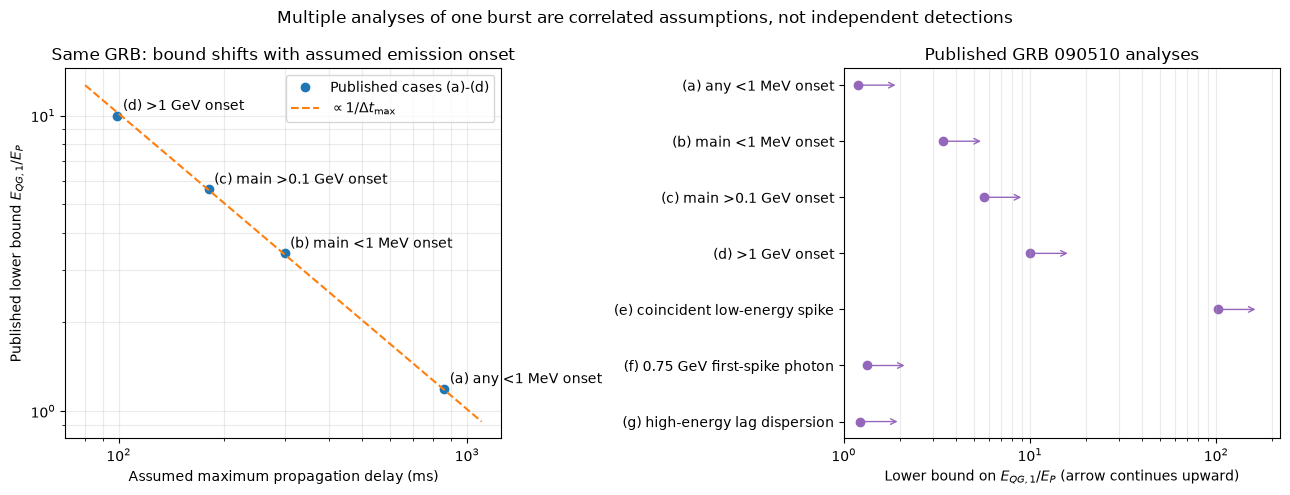

In [8]:
from scipy.integrate import quad
from astropy.cosmology import Planck18

z_grb = 0.900
E_high_GeV, E_low_GeV = 28.0, 1e-4  # 28 GeV lower-energy bound; 0.1 MeV reference
delta_t_max_s = 0.859
H0_paper = 71 * u.km / u.s / u.Mpc
Om_paper, OL_paper = 0.27, 0.73

def j_paper(z):
    return quad(lambda zp: (1 + zp) / np.sqrt(Om_paper * (1 + zp)**3 + OL_paper), 0, z)[0]

J_grb = j_paper(z_grb)
H0_paper_s = H0_paper.to_value(1 / u.s)
eqg_bound_GeV = (E_high_GeV - E_low_GeV) * J_grb / (H0_paper_s * delta_t_max_s)
eqg_bound_planck = eqg_bound_GeV / EP.to_value(u.GeV)

# Independent numerical integration check by a fine-grid trapezoid rule.
z_grid = np.linspace(0, z_grb, 20001)
J_trapezoid = np.trapezoid((1 + z_grid) / np.sqrt(Om_paper * (1 + z_grid)**3 + OL_paper), z_grid)
assert np.isclose(J_grb, J_trapezoid, rtol=1e-8)
assert np.isclose(eqg_bound_planck, 1.19, rtol=0.01)

# Recompute with the notebook's stated Planck18 cosmology; this is not the paper's exact setup.
J_planck18_s = quad(
    lambda zp: (1 + zp) / Planck18.H(zp).to_value(1 / u.s), 0, z_grb
)[0]
eqg_planck18_planck = (
    (E_high_GeV - E_low_GeV) * J_planck18_s / delta_t_max_s
) / EP.to_value(u.GeV)
photon_ratio = (31 * u.GeV / EP).decompose().value
print(f'Paper-cosmology reconstruction: {eqg_bound_planck:.4f} E_P; published conservative row (a): 1.19 E_P')
print(f'Planck18 recomputation with same event inputs: {eqg_planck18_planck:.4f} E_P')
print(f'Observed 31 GeV photon / Planck energy: {photon_ratio:.3e}; squared ratio: {photon_ratio**2:.3e}')

# Table 2 alternatives: the same event/photon, under different emission-time assumptions or methods.
grb_limits = pd.DataFrame([
    {'case':'(a) any <1 MeV onset','lag_upper_ms':859,'bound_Eqg_over_EP':1.19,'method':'Most conservative onset'},
    {'case':'(b) main <1 MeV onset','lag_upper_ms':299,'bound_Eqg_over_EP':3.42,'method':'Later emission onset'},
    {'case':'(c) main >0.1 GeV onset','lag_upper_ms':181,'bound_Eqg_over_EP':5.63,'method':'Later emission onset'},
    {'case':'(d) >1 GeV onset','lag_upper_ms':99,'bound_Eqg_over_EP':10.0,'method':'Later emission onset'},
    {'case':'(e) coincident low-energy spike','lag_upper_ms':10,'bound_Eqg_over_EP':102.0,'method':'Least conservative source-time association'},
    {'case':'(f) 0.75 GeV first-spike photon','lag_upper_ms':19,'bound_Eqg_over_EP':1.33,'method':'Opposite-sign delay analysis'},
    {'case':'(g) high-energy lag dispersion','lag_upper_ms':np.nan,'bound_Eqg_over_EP':1.22,'method':'99% bound: 30 ms/GeV, not a single lag'},
])
display(grb_limits)

# Rows (a)-(d) must approximately follow the inverse-lag scaling for a fixed photon and redshift.
conservative_cases = grb_limits.iloc[:4]
scaling_products = conservative_cases.lag_upper_ms * conservative_cases.bound_Eqg_over_EP
assert np.allclose(scaling_products, scaling_products.mean(), rtol=0.04)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].loglog(conservative_cases.lag_upper_ms, conservative_cases.bound_Eqg_over_EP, 'o', label='Published cases (a)-(d)')
lag_curve = np.logspace(np.log10(80), np.log10(1100), 200)
axes[0].loglog(lag_curve, scaling_products.mean() / lag_curve, '--', label=r'$\propto1/\Delta t_{\max}$')
for row in conservative_cases.itertuples():
    axes[0].annotate(row.case, (row.lag_upper_ms, row.bound_Eqg_over_EP), xytext=(4, 4), textcoords='offset points')
axes[0].set(xlabel='Assumed maximum propagation delay (ms)', ylabel=r'Published lower bound $E_{QG,1}/E_P$',
            title='Same GRB: bound shifts with assumed emission onset')
axes[0].grid(True, which='both', alpha=.25); axes[0].legend()
for y, row in enumerate(grb_limits.itertuples()):
    value = row.bound_Eqg_over_EP
    axes[1].scatter(value, y, color='tab:purple')
    axes[1].annotate('', xy=(value * 1.65, y), xytext=(value * 1.02, y),
                     arrowprops={'arrowstyle':'->','color':'tab:purple'})
axes[1].set_xscale('log')
axes[1].set_yticks(range(len(grb_limits)), grb_limits.case)
axes[1].invert_yaxis()
axes[1].set(xlim=(1, 220), xlabel=r'Lower bound on $E_{QG,1}/E_P$ (arrow continues upward)',
            title='Published GRB 090510 analyses')
axes[1].grid(True, axis='x', which='both', alpha=.25)
fig.suptitle('Multiple analyses of one burst are correlated assumptions, not independent detections')
fig.tight_layout(); plt.show()

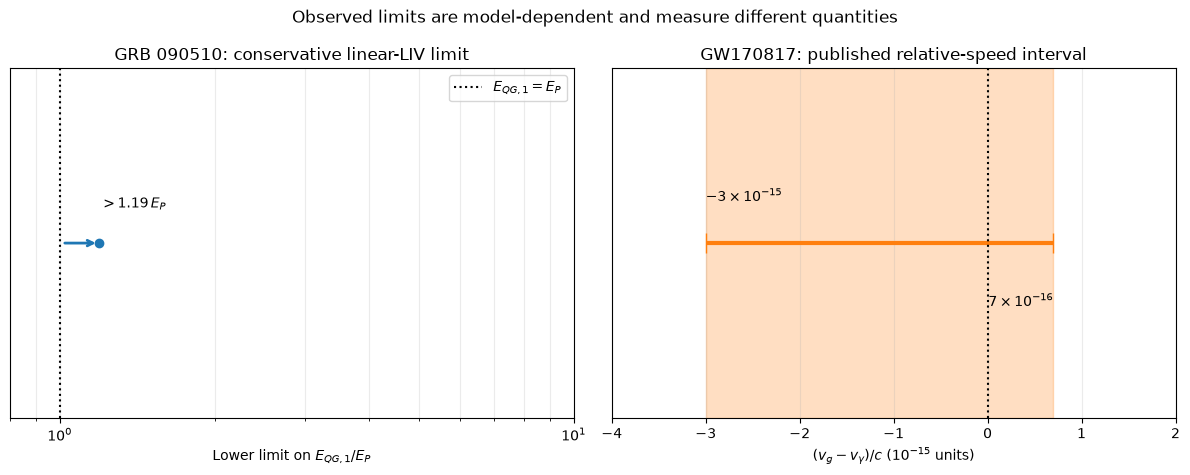

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].axvline(1, color='k', ls=':', label=r'$E_{QG,1}=E_P$')
axes[0].annotate('', xy=(1.19, 0), xytext=(1.01, 0),
                 arrowprops={'arrowstyle': '->', 'lw': 2, 'color': 'tab:blue'})
axes[0].scatter([1.19], [0], color='tab:blue', zorder=3)
axes[0].text(1.2, 0.1, r'$>1.19\,E_P$')
axes[0].set_xscale('log')
axes[0].set(xlim=(0.8, 10), ylim=(-0.5, 0.5),
            xlabel=r'Lower limit on $E_{QG,1}/E_P$',
            yticks=[], title='GRB 090510: conservative linear-LIV limit')
axes[0].grid(True, axis='x', which='both', alpha=.25)
axes[0].legend()

lo, hi = -3.0, 0.7
axes[1].axvspan(lo, hi, color='tab:orange', alpha=.25)
axes[1].hlines(0, lo, hi, color='tab:orange', lw=3)
axes[1].plot([lo, hi], [0, 0], '|', color='tab:orange', ms=15)
axes[1].axvline(0, color='k', ls=':')
axes[1].set(xlim=(-4, 2), ylim=(-0.5, 0.5),
            xlabel=r'$(v_g-v_\gamma)/c$ ($10^{-15}$ units)',
            yticks=[], title='GW170817: published relative-speed interval')
axes[1].grid(True, axis='x', alpha=.25)
axes[1].text(lo, 0.12, r'$-3\times10^{-15}$', ha='left')
axes[1].text(hi, -0.18, r'$7\times10^{-16}$', ha='right')
fig.suptitle('Observed limits are model-dependent and measure different quantities')
fig.tight_layout()
plt.show()

## 8. Evidence and references

No direct quantum-gravity observation is included. Gravitational-wave, black-hole imaging, and cosmological measurements test classical/semiclassical gravity and constrain some model-dependent departures; they do not select a complete theory. Approach assumptions, strengths, limitations, and references are discussed in [the companion research section](../premium/quantum_gravity.md). The source links include Donoghue (EFT), Wallace (low-energy status), Ashtekar & Bianchi (loop quantum gravity), Polchinski (string theory), Eichhorn (asymptotic safety), Ambjørn et al. (causal dynamical triangulations), and Liberati & Maccione (conditional phenomenology).